# What Determines Pay? — Ask A Manager Salary Survey (2021)
**Digitalley Drive · Data Science Track · Capstone (EDA and Data Cleaning)**
**Author:** Nwogbe Onyinyechi Victoria

This notebook cleans the crowd-sourced Ask A Manager salary survey and answers six questions about what relates to pay.

| Section | What it covers |
|---|---|
| 1 | Setup and loading the data |
| 2 | Data cleaning, with every decision explained |
| 3 | Univariate overview of the cleaned data |
| 4 | The six analytical questions, each with a chart and a written finding |
| 5 | Summary of insights in plain business language |

**Scope used for the analysis (also stated in my submission email):** respondents who reported their salary in **USD**, with salaries between **$10,000 and $1,000,000** a year. Mixing currencies without conversion would give misleading comparisons, so I restricted to one currency instead of guessing exchange rates.

## 1. Setup and loading the data

In [6]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
NAVY, TEAL, GREY, RED = "#1B4965", "#2A9D8F", "#8A99A8", "#C8553D"
money = mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}K")   # axis labels like $90K
pd.set_option("display.max_columns", 30, "display.width", 140)

In [7]:
# Upload the Excel file to Colab first (left sidebar > Files), then run this cell.
import os
import pandas as pd

path = "/content/Copy of Ask A Manager Salary Survey 2021 (Responses).xlsx"
if not os.path.exists(path):                  # running locally instead of Colab
    path = "Copy of Ask A Manager Salary Survey 2021 (Responses).xlsx"
raw = pd.read_excel(path)
print("Rows, columns:", raw.shape)
raw.head(3)

Rows, columns: (28225, 18)


,Timestamp,How old are you?,What industry do you work in?,Job title,"If your job title needs additional context, please clarify here:","What is your annual salary? (You'll indicate the currency in a later question. If you are part-time or hourly, please enter an annualized equivalent -- what you would earn if you worked the job 40 hours a week, 52 weeks a year.)","How much additional monetary compensation do you get, if any (for example, bonuses or overtime in an average year)? Please only include monetary compensation here, not the value of benefits.",Please indicate the currency,"If ""Other,"" please indicate the currency here:","If your income needs additional context, please provide it here:",What country do you work in?,"If you're in the U.S., what state do you work in?",What city do you work in?,How many years of professional work experience do you have overall?,How many years of professional work experience do you have in your field?,What is your highest level of education completed?,What is your gender?,What is your race? (Choose all that apply.)
0,2021-04-27 11:02:09.743,25-34,Education (Higher Education),Research and Instruction Librarian,NaN,55000,0.0,USD,NaN,NaN,United States,Massachusetts,Boston,5-7 years,5-7 years,Master's degree,Woman,White
1,2021-04-27 11:02:21.562,25-34,Computing or Tech,Change & Internal Communications Manager,NaN,54600,4000.0,GBP,NaN,NaN,United Kingdom,NaN,Cambridge,8 - 10 years,5-7 years,College degree,Non-binary,White
2,2021-04-27 11:02:38.125,25-34,"Accounting, Banking & Finance",Marketing Specialist,NaN,34000,NaN,USD,NaN,NaN,US,Tennessee,Chattanooga,2 - 4 years,2 - 4 years,College degree,Woman,White


### Shorter column names
The original column names are full survey questions (some over 200 characters). I rename them by position to short, readable names.

In [8]:
new_names = ["Timestamp", "Age", "Industry", "Job Title", "Additional Job Context", "Salary",
             "Additional Compensation", "Currency", "Other Currency", "Additional Income Context",
             "Country", "State", "City", "Overall Experience", "Field Experience", "Education",
             "Gender", "Race"]
assert len(new_names) == raw.shape[1]
df = raw.copy()
df.columns = new_names
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28225 entries, 0 to 28224
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Timestamp                  28225 non-null  datetime64[ns]
 1   Age                        28225 non-null  object        
 2   Industry                   28139 non-null  object        
 3   Job Title                  28220 non-null  object        
 4   Additional Job Context     7293 non-null   object        
 5   Salary                     28225 non-null  int64         
 6   Additional Compensation    20850 non-null  float64       
 7   Currency                   28225 non-null  object        
 8   Other Currency             225 non-null    object        
 9   Additional Income Context  3053 non-null   object        
 10  Country                    28223 non-null  object        
 11  State                      23147 non-null  object        
 12  City

## 2. Data cleaning

### 2.1 Missing values and duplicates

In [9]:
missing = pd.DataFrame({"Missing": df.isna().sum(), "% missing": (df.isna().mean() * 100).round(1)})
print(missing.sort_values("Missing", ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())

                           Missing  % missing
Other Currency               28000       99.2
Additional Income Context    25172       89.2
Additional Job Context       20932       74.2
Additional Compensation       7375       26.1
State                         5078       18.0
Education                      241        0.9
Race                           197        0.7
Gender                         186        0.7
Industry                        86        0.3
City                            85        0.3
Job Title                        5        0.0
Country                          2        0.0
Age                              0        0.0
Timestamp                        0        0.0
Currency                         0        0.0
Salary                           0        0.0
Overall Experience               0        0.0
Field Experience                 0        0.0

Duplicate rows: 0


**Decisions on missing values**
- **Additional Job Context, Additional Income Context and Other Currency** are optional free-text boxes and are mostly empty. They are not needed for the six questions, so I keep them untouched and do not use them.
- **Additional Compensation** is blank for about a quarter of respondents. Blank most likely means no bonus, but I cannot be sure, so I do not use it and analyse base salary only.
- **State** is only relevant for US respondents, so blanks are expected. It is only used in Question 3, which is restricted to the US.
- **Education and Gender** are replaced with an explicit **"Not stated"** label so those people stay in the data and are not mistaken for a real category.
- **Industry, Job Title and Race** blanks are small. Those rows are dropped only in the specific analysis that needs the field.
- There are **no duplicate rows**, so nothing is removed.

### 2.2 Survey period

In [10]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
print(df["Timestamp"].dt.year.value_counts().sort_index())

# The survey form stayed open after 2021, so a small number of later responses exist.
# They are the same survey and the same questions, so by default they are kept.
# Set this to True to limit the analysis to responses submitted in 2021 only.
RESTRICT_TO_2021 = False
if RESTRICT_TO_2021:
    df = df[df["Timestamp"].dt.year == 2021].copy()
print("Rows kept:", len(df))

Timestamp
2021    27597
2022      325
2023       79
2024      103
2025       83
2026       38
Name: count, dtype: int64
Rows kept: 28225


### 2.3 Salary and compensation: text to numbers

In [11]:
def to_number(s):
    # Handles values stored as text with commas or currency symbols, e.g. "55,000" or "$55,000"
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")

df["Salary"] = to_number(df["Salary"])
df["Additional Compensation"] = to_number(df["Additional Compensation"])
print("Salary values that could not be converted:", df["Salary"].isna().sum())
df["Salary"].describe().apply(lambda v: f"{v:,.0f}")

Salary values that could not be converted: 0


,Salary
count,"28,225"
mean,"371,138"
std,"36,133,664"
min,0
25%,"54,000"
50%,"75,000"
75%,"109,450"
max,"6,000,070,000"


### 2.4 Standardise text columns and country names

In [12]:
# Trim stray spaces in every text column
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

print("Unique country spellings before cleaning:", df["Country"].nunique())

def clean_country(value):
    if pd.isna(value):
        return np.nan
    v = re.sub(r"[.]", "", str(value).lower()).strip()
    v = re.sub(r"\s+", " ", v)
    if v in {"us", "usa", "u s", "u s a", "america", "the us", "the usa", "the united states",
             "united states", "united states of america", "united state", "unites states", "united sates"} \
       or "united states" in v or v.startswith("usa") or v.startswith("us "):
        return "United States"
    if v in {"uk", "united kingdom", "great britain", "england", "scotland", "wales", "northern ireland",
             "england uk", "uk england", "britain"} or "united kingdom" in v:
        return "United Kingdom"
    if v in {"the netherlands", "netherlands", "holland"}:
        return "Netherlands"
    return v.title()

df["Country Clean"] = df["Country"].apply(clean_country)
print("Unique country values after cleaning:", df["Country Clean"].nunique())
df["Country Clean"].value_counts().head(10)

Unique country spellings before cleaning: 329
Unique country values after cleaning: 216


,count
Country Clean,
United States,23223
Canada,1684
United Kingdom,1582
Australia,390
Germany,198
Ireland,125
New Zealand,123
Netherlands,89
France,69


The United States alone appeared under many spellings. After standardising, the top countries are consistent. Country is used to describe the data. The analytical questions use the **USD** subset, which is mostly US respondents.

### 2.5 Currency

In [13]:
print(df["Currency"].value_counts())
usd_share = (df["Currency"] == "USD").mean()
print(f"\nUSD responses: {usd_share:.1%} of all rows")

Currency
USD        23497
CAD         1677
GBP         1598
EUR          654
AUD/NZD      505
Other        176
CHF           37
SEK           37
JPY           23
ZAR           17
HKD            4
Name: count, dtype: Int64

USD responses: 83.2% of all rows


Salaries are reported in many currencies. Comparing them without conversion would be misleading, and approximate exchange rates (especially for the combined "AUD/NZD" option) would add errors of their own. **I keep USD responses only.** That is about 83% of the survey and a large sample for every question.

### 2.6 Experience ranges: order and numeric midpoints

In [14]:
# The labels use inconsistent spacing and hyphens ("2 - 4 years" vs "5-7 years"), so normalise first
for col in ["Overall Experience", "Field Experience"]:
    df[col] = df[col].str.replace(r"\s*-\s*", "-", regex=True)

exp_order = ["1 year or less", "2-4 years", "5-7 years", "8-10 years",
             "11-20 years", "21-30 years", "31-40 years", "41 years or more"]
exp_mid = dict(zip(exp_order, [0.5, 3, 6, 9, 15.5, 25.5, 35.5, 41]))   # midpoint of each range, in years

for col in ["Overall Experience", "Field Experience"]:
    df[col] = pd.Categorical(df[col], categories=exp_order, ordered=True)
df["Overall Years"] = df["Overall Experience"].map(exp_mid).astype(float)
df["Field Years"] = df["Field Experience"].map(exp_mid).astype(float)
print(df["Overall Experience"].value_counts().reindex(exp_order))

Overall Experience
1 year or less       572
2-4 years           3072
5-7 years           4903
8-10 years          5388
11-20 years         9644
21-30 years         3649
31-40 years          871
41 years or more     126
Name: count, dtype: int64


### 2.7 Education, gender and race

In [15]:
# Education: shorter label for the professional degree, and an explicit label for blanks
df["Education"] = df["Education"].replace({"Professional degree (MD, JD, etc.)": "Professional degree"}).fillna("Not stated")
edu_order = ["High School", "Some college", "College degree", "Master's degree", "PhD", "Professional degree", "Not stated"]

# Gender: two "prefer not to answer" variants are merged, blanks labelled
df["Gender"] = (df["Gender"].replace({"Prefer not to answer": "Other or prefer not to answer"})
                .fillna("Not stated"))

# Race is a "choose all that apply" field: several answers are packed into one cell.
# I create one yes/no column per category. A person who chose two categories counts in both.
race_patterns = {
    "White": r"\bWhite\b",
    "Asian": r"Asian or Asian American",
    "Black": r"Black or African American",
    "Hispanic/Latino": r"Hispanic, Latino, or Spanish origin",
    "Middle Eastern/N. African": r"Middle Eastern or Northern African",
    "Native American/Alaska Native": r"Native American or Alaska Native",
    "Other/prefer not to say": r"Another option not listed here or prefer not to answer",
}
for label, pattern in race_patterns.items():
    df["Race: " + label] = df["Race"].fillna("").str.contains(pattern, regex=True)
df["Race Selections"] = df["Race"].fillna("").str.count(",") + df["Race"].notna()
print("Respondents choosing more than one race option:", f"{(df['Race Selections'] > 1).mean():.1%} of those who answered")
print(df["Education"].value_counts())

Respondents choosing more than one race option: 6.6% of those who answered
Education
College degree         13572
Master's degree         8899
Some college            2097
PhD                     1428
Professional degree     1329
High School              659
Not stated               241
Name: count, dtype: Int64


Because race is multi-select, the groups **overlap** and group counts add up to more than the number of respondents. Race comparisons in this notebook are therefore group-by-group medians, and I always show the sample size next to each result.

### 2.8 Outliers and implausible salaries (USD subset)

In [16]:
usd = df[df["Currency"] == "USD"].copy()
print("USD rows:", len(usd))
print(usd["Salary"].describe().apply(lambda v: f"{v:,.0f}"))

low, high = 10_000, 1_000_000
n_low, n_high = (usd["Salary"] < low).sum(), (usd["Salary"] > high).sum()
print(f"\nBelow ${low:,}: {n_low} rows   Above ${high:,}: {n_high} rows")
usd.loc[(usd["Salary"] < low) | (usd["Salary"] > high), ["Job Title", "Industry", "Salary"]].sort_values("Salary").head(8)

USD rows: 23497
count         23,497
mean          99,165
std          753,942
min                0
25%           56,000
50%           78,000
75%          112,000
max      102,000,000
Name: Salary, dtype: object

Below $10,000: 127 rows   Above $1,000,000: 18 rows


,Job Title,Industry,Salary
10362,Executive Director,Nonprofits,0
8739,"""mum"" ;)",Stay-at-home parent,0
12615,Attorney,Law,0
13537,Student teacher,Education (Primary/Secondary),0
15238,Product Marketer,Computing or Tech,0
15334,Househusband,Education (Primary/Secondary),0
28121,<NA>,<NA>,0
27996,<NA>,I'm currently a student and don't have a job,0


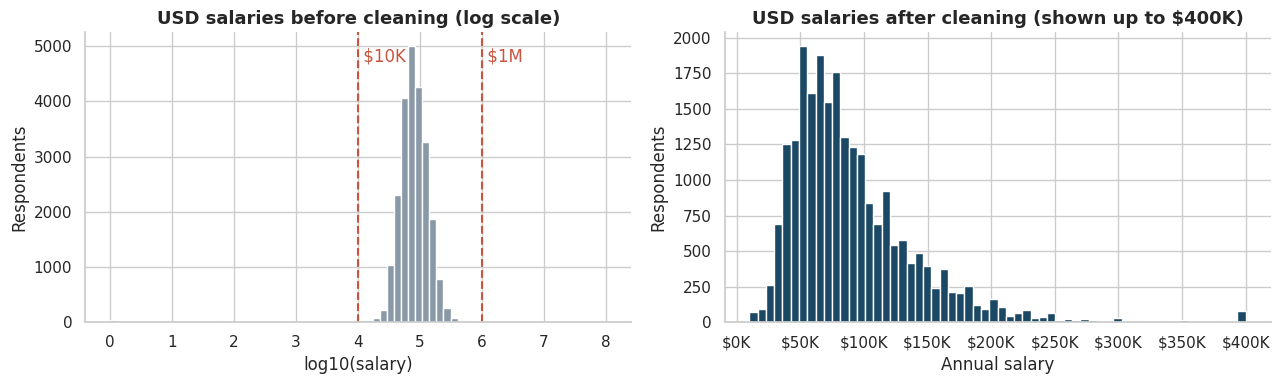

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(usd["Salary"].clip(lower=1)), bins=70, color=GREY)
for x, label in [(np.log10(low), "$10K"), (np.log10(high), "$1M")]:
    axes[0].axvline(x, color=RED, ls="--"); axes[0].text(x, axes[0].get_ylim()[1]*0.9, " "+label, color=RED)
axes[0].set_title("USD salaries before cleaning (log scale)"); axes[0].set_xlabel("log10(salary)"); axes[0].set_ylabel("Respondents")

kept = usd[usd["Salary"].between(low, high)]
axes[1].hist(kept["Salary"].clip(upper=400_000), bins=60, color=NAVY)
axes[1].xaxis.set_major_formatter(money)
axes[1].set_title("USD salaries after cleaning (shown up to $400K)"); axes[1].set_xlabel("Annual salary"); axes[1].set_ylabel("Respondents")
plt.tight_layout(); plt.show()

**Decision:** I removed salaries **below $10,000** and **above $1,000,000** a year.
- Values such as 0 or a few hundred dollars cannot be a genuine full-time annual salary. They are likely monthly amounts, hourly rates, or typing errors.
- Values in the tens or hundreds of millions are clearly entry errors. A single one of them distorts an average badly (before cleaning, one industry (Utilities & Telecommunications) showed a mean salary of about $470,000 against a median of about $85,000).
- The cut-offs remove only a small share of the USD rows, so the findings are not driven by this choice. **Medians** are used as the main measure throughout because they are robust to extreme values.

In [18]:
analysis = usd[usd["Salary"].between(low, high)].copy()
print(f"Rows used for the analysis: {len(analysis):,}  ({len(usd) - len(analysis)} removed as outliers)")
print(f"Median salary: ${analysis['Salary'].median():,.0f}    Mean salary: ${analysis['Salary'].mean():,.0f}")

Rows used for the analysis: 23,352  (145 removed as outliers)
Median salary: $78,500    Mean salary: $91,380


## 3. Overview of the cleaned data

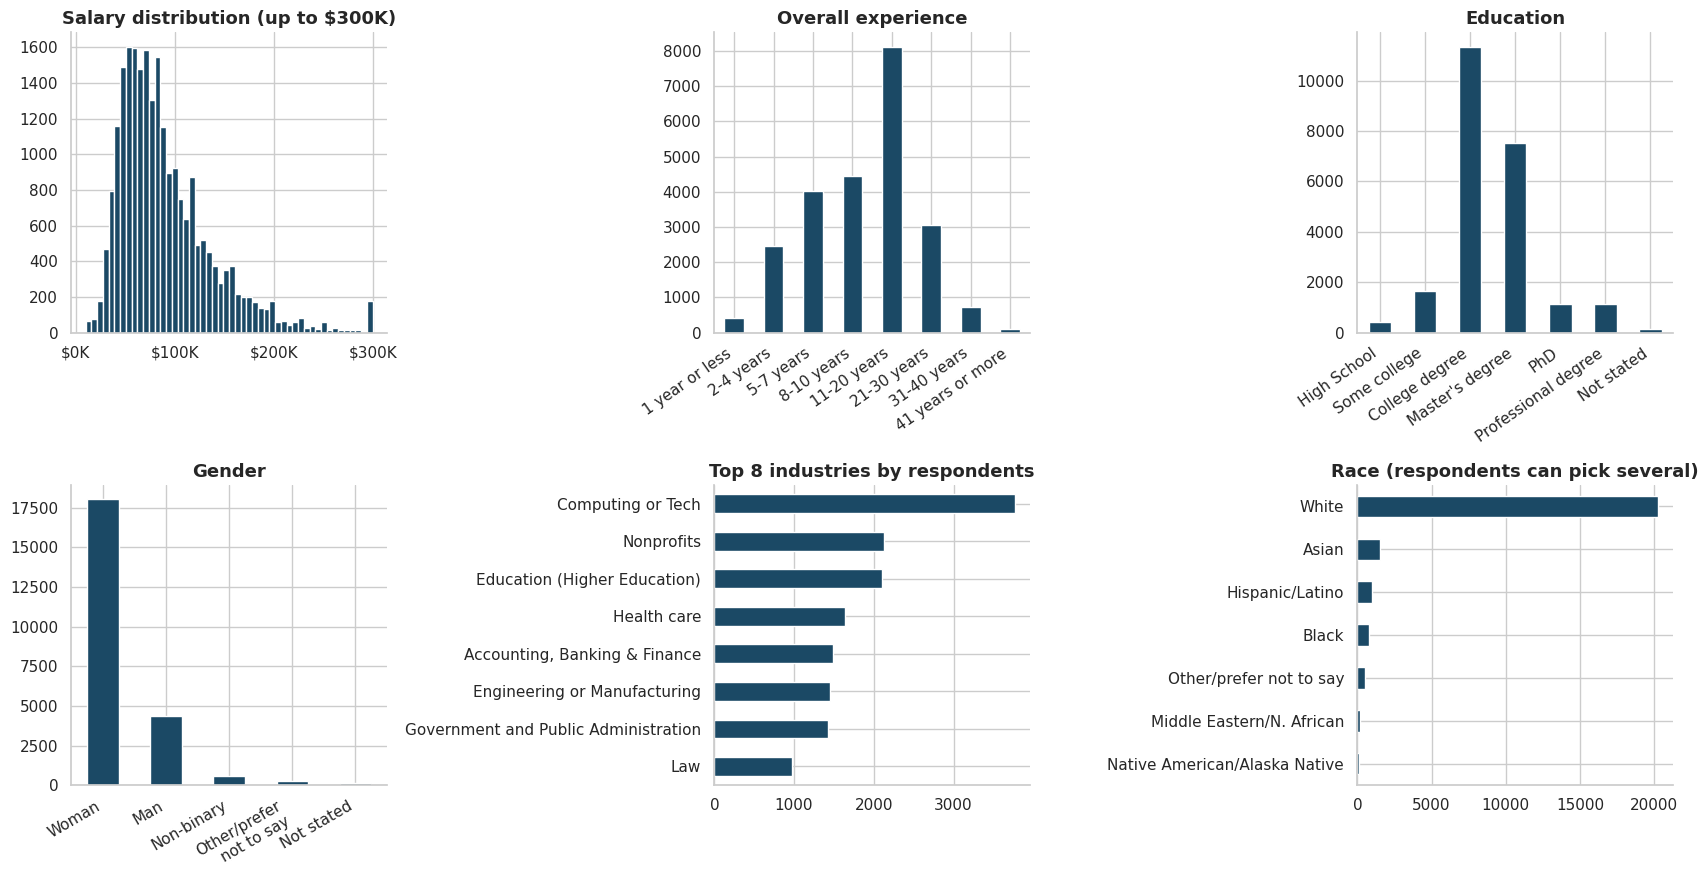

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
def bar(ax, s, title, color=NAVY, horizontal=False):
    (s.plot.barh if horizontal else s.plot.bar)(ax=ax, color=color)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")

axes[0,0].hist(analysis["Salary"].clip(upper=300_000), bins=50, color=NAVY)
axes[0,0].xaxis.set_major_formatter(money); axes[0,0].set_title("Salary distribution (up to $300K)")
bar(axes[0,1], analysis["Overall Experience"].value_counts().reindex(exp_order), "Overall experience")
plt.setp(axes[0,1].get_xticklabels(), rotation=35, ha="right")
bar(axes[0,2], analysis["Education"].value_counts().reindex(edu_order), "Education")
plt.setp(axes[0,2].get_xticklabels(), rotation=35, ha="right")
bar(axes[1,0], analysis["Gender"].value_counts().rename({"Other or prefer not to answer": "Other/prefer\nnot to say"}), "Gender"); plt.setp(axes[1,0].get_xticklabels(), rotation=30, ha="right")
bar(axes[1,1], analysis["Industry"].value_counts().head(8).iloc[::-1], "Top 8 industries by respondents", horizontal=True)
race_counts = pd.Series({k: analysis["Race: " + k].sum() for k in race_patterns}).sort_values()
bar(axes[1,2], race_counts, "Race (respondents can pick several)", horizontal=True)
plt.tight_layout(); plt.show()

**What the cleaned data looks like**
- **23,352 respondents** are used in the analysis. The typical (median) salary is **$78,500**, and the average is higher at $91,380 because a minority of very high earners pull it up (the distribution leans to the right).
- The sample is **77% women** and about **87% selected White**, so it is not a mirror of the whole workforce.
- Most respondents hold a college or Master's degree and have 8 to 20 years of experience. **Computing or Tech** is the largest industry (3,771 respondents), ahead of Nonprofits and Higher Education.
- Because the sample is uneven, every comparison below shows the number of respondents (n) and uses **medians** rather than averages.

## 4. The six questions

### Question 1. Which industry pays the most?

In [20]:
industry_stats = (analysis.dropna(subset=["Industry"]).groupby("Industry")["Salary"]
                  .agg(Respondents="count", Median="median", Mean="mean")
                  .query("Respondents >= 100").sort_values("Median", ascending=False))
print("Industries with at least 100 respondents:", len(industry_stats))
industry_stats.head(10).round(0)

Industries with at least 100 respondents: 24


,Respondents,Median,Mean
Industry,,,
Computing or Tech,3771,120000.0,129318.0
Law,969,95000.0,120215.0
Engineering or Manufacturing,1448,90250.0,97783.0
Business or Consulting,700,90000.0,103949.0
Utilities & Telecommunications,267,85000.0,91786.0
Health care,1634,80000.0,91488.0
"Accounting, Banking & Finance",1491,80000.0,92228.0
"Marketing, Advertising & PR",930,79000.0,90835.0
Government and Public Administration,1425,78000.0,83053.0


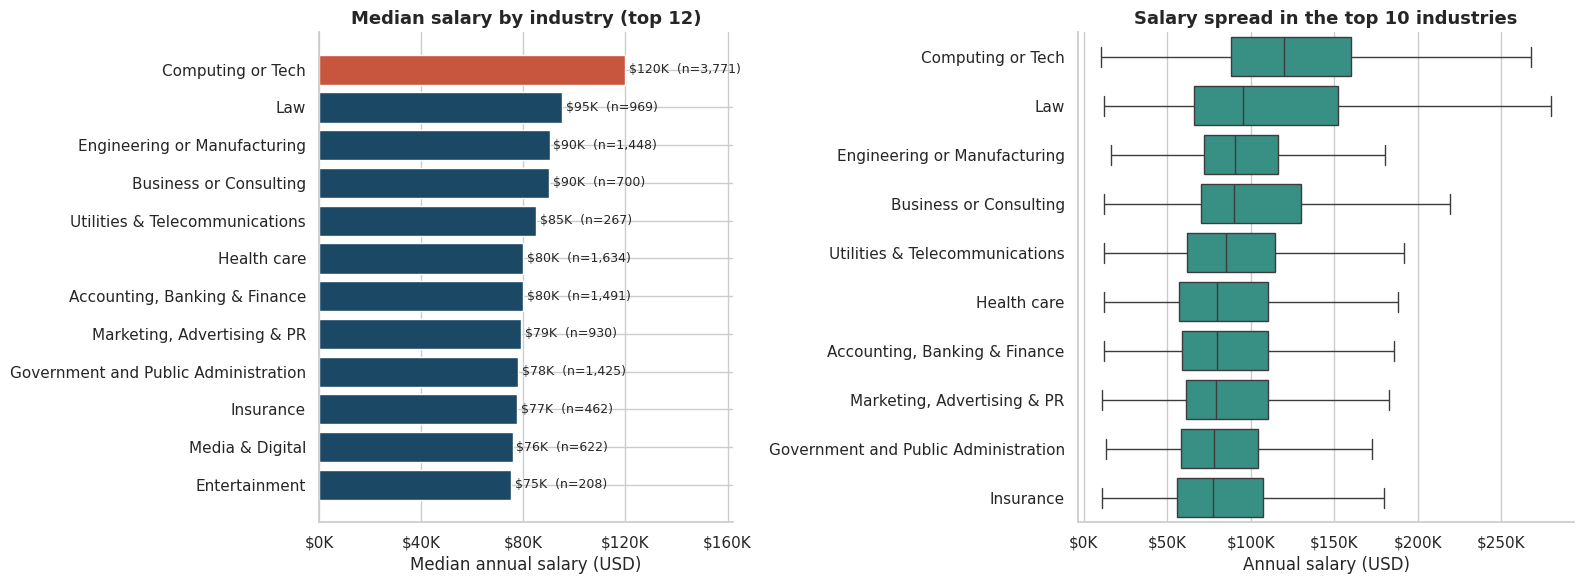

In [21]:
top = industry_stats.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.2]})
bars = axes[0].barh(top.index, top["Median"], color=[RED if i == len(top)-1 else NAVY for i in range(len(top))])
for b, n, m in zip(bars, top["Respondents"], top["Median"]):
    axes[0].text(m + 1500, b.get_y() + b.get_height()/2, f"${m/1000:,.0f}K  (n={n:,})", va="center", fontsize=9)
axes[0].xaxis.set_major_formatter(money); axes[0].set_xlim(0, top["Median"].max() * 1.35); axes[0].xaxis.set_major_locator(mtick.MultipleLocator(40000))
axes[0].set_title("Median salary by industry (top 12)"); axes[0].set_xlabel("Median annual salary (USD)")

order = industry_stats.head(10).index
sns.boxplot(data=analysis[analysis["Industry"].isin(order)], y="Industry", x="Salary", order=order,
            color=TEAL, showfliers=False, ax=axes[1])
axes[1].xaxis.set_major_formatter(money); axes[1].set_title("Salary spread in the top 10 industries")
axes[1].set_xlabel("Annual salary (USD)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Finding: Computing or Tech pays the most, by a clear margin.**
- Its median salary is **$120,000** (n = 3,771), about 50% above the overall median of $78,500.
- **Law** is second at **$95,000**, then **Engineering or Manufacturing** ($90,250) and **Business or Consulting** ($90,000).
- Law has a wide spread. Its average ($120K) is far above its median ($95K), which means a group of very high earners sits above a more typical group.
- Most other industries cluster between **$75,000 and $85,000**, so the real gap is between Tech and everyone else.

### Question 2. How does salary increase with years of experience?

In [22]:
exp_stats = (analysis.groupby("Overall Experience", observed=True)["Salary"]
             .agg(Respondents="count", Q1=lambda s: s.quantile(.25), Median="median", Q3=lambda s: s.quantile(.75), Mean="mean")
             .reindex(exp_order))
exp_stats["Median change vs previous"] = exp_stats["Median"].pct_change().map(lambda v: f"{v:+.0%}" if pd.notna(v) else "")
exp_stats.round(0)

,Respondents,Q1,Median,Q3,Mean,Median change vs previous
Overall Experience,,,,,,
1 year or less,426,41600.0,57000.0,78000.0,67136.0,
2-4 years,2451,45000.0,61500.0,84000.0,70407.0,+8%
5-7 years,4019,52000.0,70000.0,95000.0,80411.0,+14%
8-10 years,4441,57477.0,77000.0,108000.0,88877.0,+10%
11-20 years,8122,62400.0,86000.0,123000.0,99406.0,+12%
21-30 years,3054,65000.0,91000.0,130600.0,105383.0,+6%
31-40 years,729,62000.0,90000.0,125000.0,102774.0,-1%
41 years or more,110,60000.0,90750.0,124250.0,97607.0,+1%


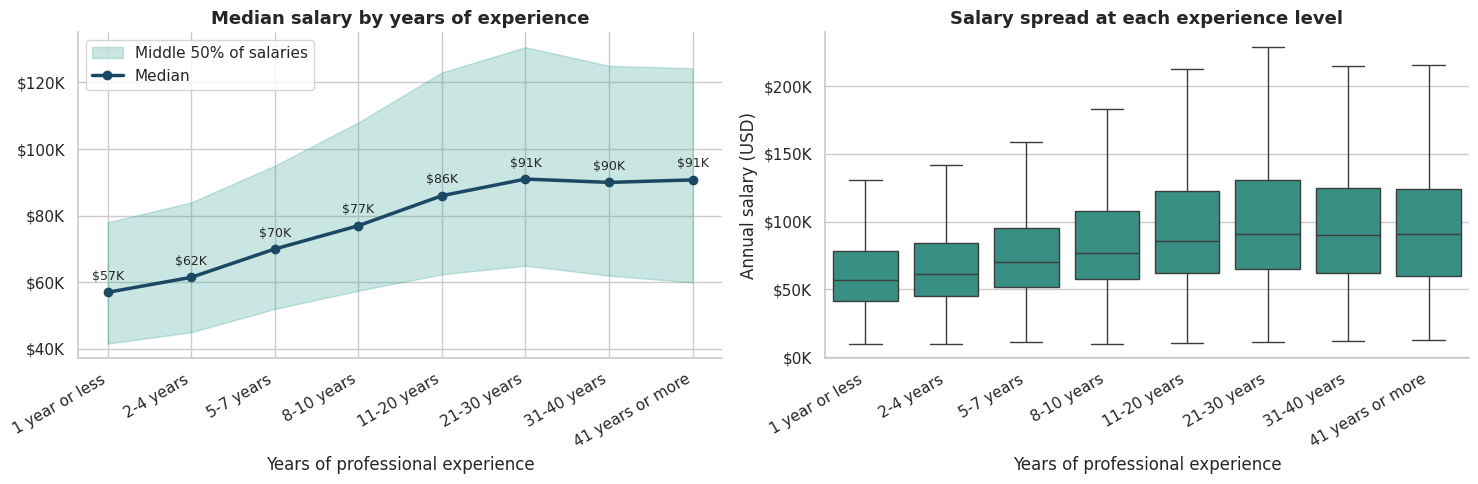

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = range(len(exp_order))
axes[0].fill_between(x, exp_stats["Q1"], exp_stats["Q3"], color=TEAL, alpha=.25, label="Middle 50% of salaries")
axes[0].plot(x, exp_stats["Median"], marker="o", color=NAVY, lw=2.5, label="Median")
for i, m in enumerate(exp_stats["Median"]):
    axes[0].annotate(f"${m/1000:,.0f}K", (i, m), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
axes[0].set_xticks(list(x)); axes[0].set_xticklabels(exp_order, rotation=30, ha="right")
axes[0].yaxis.set_major_formatter(money); axes[0].legend()
axes[0].set_title("Median salary by years of experience"); axes[0].set_xlabel("Years of professional experience")
sns.boxplot(data=analysis, x="Overall Experience", y="Salary", order=exp_order, color=TEAL, showfliers=False, ax=axes[1])
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right"); axes[1].yaxis.set_major_formatter(money)
axes[1].set_title("Salary spread at each experience level"); axes[1].set_xlabel("Years of professional experience"); axes[1].set_ylabel("Annual salary (USD)")
plt.tight_layout(); plt.show()

**Finding: salary rises steadily with experience for the first two decades, then levels off.**
- The median grows from **$57,000** (1 year or less) to **$91,000** (21–30 years), about **60% higher**.
- Each step up to 11–20 years adds roughly **8% to 14%** to the median. The biggest jump is at 5–7 years (+14%).
- After 21–30 years pay stops rising. The medians for 31–40 years ($90,000) and 41+ years ($90,750) are flat.
- The **spread widens** with experience. The middle half of earners ranges from $42K to $78K at the start and from $65K to $131K at 21–30 years, so experience raises the ceiling more than the floor.

### Question 3. How do salaries compare for the same role in different locations?
I compare the **same job title** across **US states**. Within a single country and currency, the role is the same and only the location changes. I use the three most common job titles and only show states with at least 10 respondents for a role.

In [24]:
analysis["Job Clean"] = analysis["Job Title"].str.lower().str.strip()
us = analysis[analysis["Country Clean"] == "United States"].dropna(subset=["State"]).copy()
roles = ["software engineer", "project manager", "teacher"]
print(us["Job Clean"].value_counts().head(6))

role_state = (us[us["Job Clean"].isin(roles)].groupby(["Job Clean", "State"])["Salary"]
              .agg(n="count", median="median").reset_index().query("n >= 10"))
se = role_state[role_state["Job Clean"] == "software engineer"].sort_values("median", ascending=False)
se.round(0)

Job Clean
software engineer           305
project manager             231
senior software engineer    209
director                    191
program manager             171
executive assistant         149
Name: count, dtype: Int64


,Job Clean,State,n,median
63,software engineer,New York,51,160000.0
42,software engineer,California,82,149500.0
73,software engineer,Washington,25,140000.0
55,software engineer,Massachusetts,18,130000.0
66,software engineer,Oregon,12,120000.0
70,software engineer,Texas,15,113000.0


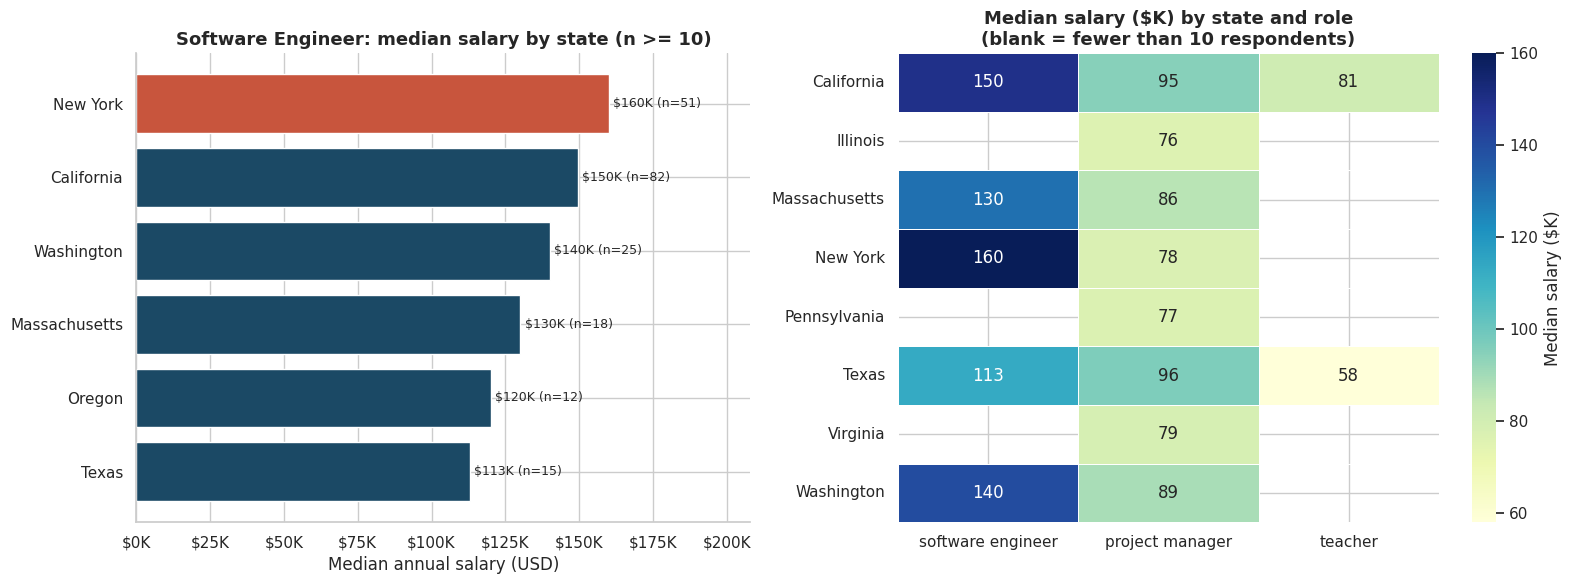

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.1]})
s = se.sort_values("median")
bars = axes[0].barh(s["State"], s["median"], color=[RED if v == s["median"].max() else NAVY for v in s["median"]])
for b, n, m in zip(bars, s["n"], s["median"]):
    axes[0].text(m + 1500, b.get_y() + b.get_height()/2, f"${m/1000:,.0f}K (n={n})", va="center", fontsize=9)
axes[0].xaxis.set_major_formatter(money); axes[0].set_xlim(0, s["median"].max() * 1.3)
axes[0].set_title("Software Engineer: median salary by state (n >= 10)"); axes[0].set_xlabel("Median annual salary (USD)")

top_states = us["State"].value_counts().head(12).index
pivot = (role_state[role_state["State"].isin(top_states)]
         .pivot(index="State", columns="Job Clean", values="median").reindex(columns=roles))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Median salary ($K)"},
            linewidths=.5, ax=axes[1])
axes[1].set_title("Median salary ($K) by state and role\n(blank = fewer than 10 respondents)")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Finding: location matters a lot, and it matters differently for each role.**
- **Software Engineers:** New York has the highest median at **$160,000** (n = 51), followed by California at $149,500 (n = 82) and Washington at $140,000. Texas is the lowest of the six states shown at $113,000, so New York pays about **42% more** than Texas for the same job title.
- **Project Managers:** the ranking changes. Texas ($96K) and California ($95K) lead, and New York ($78K) is near the bottom of the states shown.
- **Teachers:** California ($81K) pays about 40% more than Texas ($58K).
- **Caution:** some state samples are small (n = 12 to 82), and the figures are not adjusted for cost of living. Treat them as strong hints, not exact prices.

### Question 4. How much do salaries differ by gender and years of experience?
The main comparison is **Man vs Woman**, which together make up about 96% of respondents. Non-binary and other groups are too small at each experience level to compare reliably, so they appear only in the sample-size table.

In [26]:
g2 = analysis[analysis["Gender"].isin(["Man", "Woman"])]
gx = (g2.groupby(["Overall Experience", "Gender"], observed=True)["Salary"].agg(n="count", median="median")
      .unstack("Gender").reindex(exp_order))
gap = pd.DataFrame({"Man median": gx[("median", "Man")], "Woman median": gx[("median", "Woman")],
                    "Men n": gx[("n", "Man")], "Women n": gx[("n", "Woman")]})
gap["Gap ($)"] = gap["Man median"] - gap["Woman median"]
gap["Gap (% of men's median)"] = (gap["Gap ($)"] / gap["Man median"] * 100).round(1)
overall_gap = 1 - g2[g2.Gender == "Woman"]["Salary"].median() / g2[g2.Gender == "Man"]["Salary"].median()
print(f"Overall median: men ${g2[g2.Gender=='Man']['Salary'].median():,.0f}  women ${g2[g2.Gender=='Woman']['Salary'].median():,.0f}  gap {overall_gap:.1%}")
print("\nAll gender groups (respondent counts):"); print(analysis["Gender"].value_counts().to_string())
gap.round(0)

Overall median: men $100,000  women $75,000  gap 25.0%

All gender groups (respondent counts):
Gender
Woman                            18038
Man                               4335
Non-binary                         596
Other or prefer not to answer      236
Not stated                         147


,Man median,Woman median,Men n,Women n,Gap ($),Gap (% of men's median)
Overall Experience,,,,,,
1 year or less,61250.0,57000.0,96,296,4250.0,7.0
2-4 years,70000.0,60000.0,451,1838,10000.0,14.0
5-7 years,81000.0,68000.0,682,3104,13000.0,16.0
8-10 years,95000.0,75000.0,711,3538,20000.0,21.0
11-20 years,116500.0,82000.0,1563,6308,34500.0,30.0
21-30 years,127500.0,85000.0,650,2318,42500.0,33.0
31-40 years,122000.0,85000.0,149,561,37000.0,30.0
41 years or more,115000.0,84000.0,33,75,31000.0,27.0


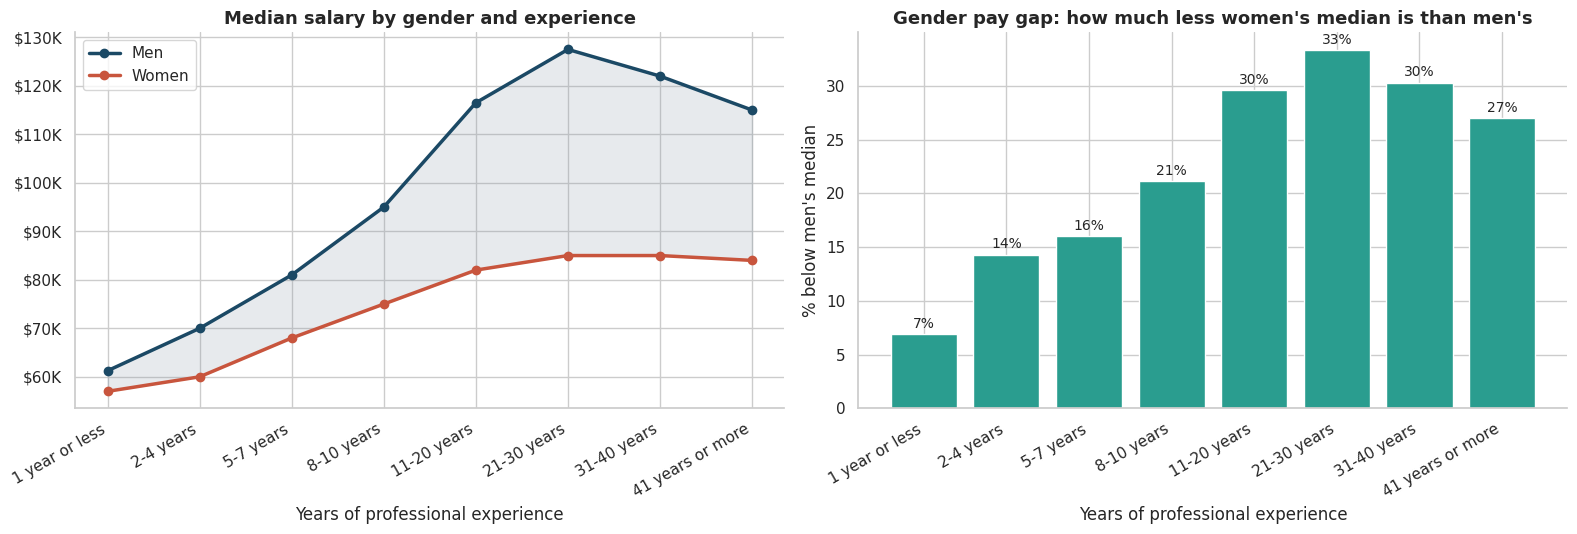

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(exp_order))
axes[0].plot(x, gap["Man median"], marker="o", color=NAVY, lw=2.5, label="Men")
axes[0].plot(x, gap["Woman median"], marker="o", color=RED, lw=2.5, label="Women")
axes[0].fill_between(x, gap["Woman median"], gap["Man median"], color=GREY, alpha=.2)
axes[0].set_xticks(x); axes[0].set_xticklabels(exp_order, rotation=30, ha="right")
axes[0].yaxis.set_major_formatter(money); axes[0].legend()
axes[0].set_title("Median salary by gender and experience"); axes[0].set_xlabel("Years of professional experience")

bars = axes[1].bar(x, gap["Gap (% of men's median)"], color=TEAL)
for b, v in zip(bars, gap["Gap (% of men's median)"]):
    axes[1].text(b.get_x() + b.get_width()/2, v + .6, f"{v:.0f}%", ha="center", fontsize=10)
axes[1].set_xticks(x); axes[1].set_xticklabels(exp_order, rotation=30, ha="right")
axes[1].set_title("Gender pay gap: how much less women's median is than men's")
axes[1].set_xlabel("Years of professional experience"); axes[1].set_ylabel("% below men's median")
plt.tight_layout(); plt.show()

**Finding: women's median salary is lower than men's at every experience level, and the gap widens with experience.**
- Overall, men's median is **$100,000** and women's is **$75,000**, so women's median is **25% lower**.
- At the start of a career the gap is small (**7%** at 1 year or less). It grows to **21%** at 8–10 years, **30%** at 11–20 years and peaks at **33%** at 21–30 years (men $127,500, women $85,000).
- Women's median flattens at about **$85,000 after 21 years**, while men's keeps rising until then.
- **Caution:** this compares medians and does not control for industry, job level or hours, so it shows that a gap exists and not why. Men are also fewer in this sample (e.g. 96 men at the 1-year level).

### Question 5. How do education level and race relate to salary?

In [28]:
edu_stats = (analysis[analysis["Education"] != "Not stated"].groupby("Education")["Salary"]
             .agg(Respondents="count", Median="median", Mean="mean").reindex(edu_order[:-1]))
race_stats = pd.DataFrame({k: {"Respondents": analysis["Race: " + k].sum(),
                               "Median": analysis.loc[analysis["Race: " + k], "Salary"].median()}
                           for k in race_patterns}).T.sort_values("Median", ascending=False)
print("EDUCATION"); print(edu_stats.round(0)); print("\nRACE (groups overlap)"); print(race_stats.round(0))

EDUCATION
                     Respondents    Median      Mean
Education                                           
High School                  419   55467.0   73076.0
Some college                1651   63000.0   78277.0
College degree             11345   75000.0   87105.0
Master's degree             7515   80000.0   91844.0
PhD                         1130   97000.0  109887.0
Professional degree         1134  120000.0  137936.0

RACE (groups overlap)
                               Respondents   Median
Asian                               1505.0  92000.0
Other/prefer not to say              521.0  86000.0
Middle Eastern/N. African            153.0  80000.0
Black                                796.0  78000.0
White                              20254.0  77000.0
Native American/Alaska Native        125.0  77000.0
Hispanic/Latino                     1011.0  75000.0


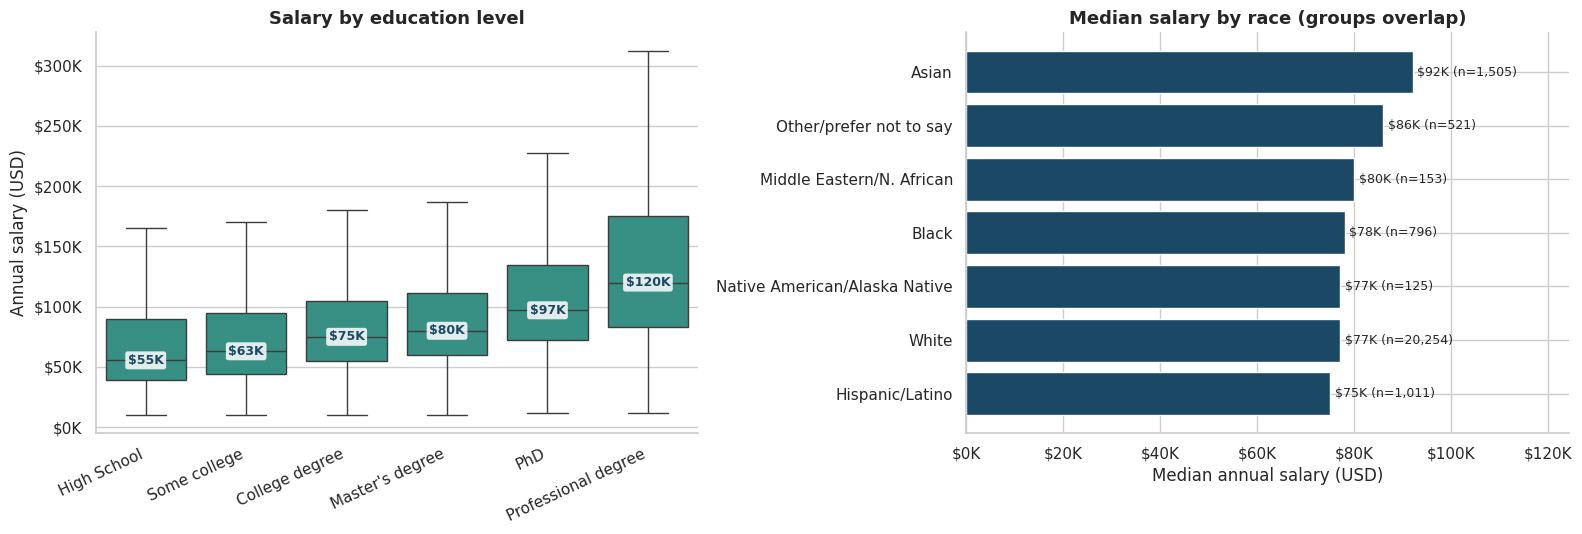

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=analysis[analysis["Education"] != "Not stated"], x="Education", y="Salary", order=edu_order[:-1],
            color=TEAL, showfliers=False, ax=axes[0])
for i, (e, row) in enumerate(edu_stats.iterrows()):
    axes[0].text(i, row["Median"], f"${row['Median']/1000:,.0f}K", va="center", ha="center", fontsize=9, color=NAVY, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.85))
plt.setp(axes[0].get_xticklabels(), rotation=25, ha="right"); axes[0].yaxis.set_major_formatter(money)
axes[0].set_title("Salary by education level"); axes[0].set_xlabel(""); axes[0].set_ylabel("Annual salary (USD)")

r = race_stats.sort_values("Median")
bars = axes[1].barh(r.index, r["Median"], color=NAVY)
for b, n, m in zip(bars, r["Respondents"], r["Median"]):
    axes[1].text(m + 1000, b.get_y() + b.get_height()/2, f"${m/1000:,.0f}K (n={int(n):,})", va="center", fontsize=9)
axes[1].xaxis.set_major_formatter(money); axes[1].set_xlim(0, r["Median"].max() * 1.35)
axes[1].set_title("Median salary by race (groups overlap)"); axes[1].set_xlabel("Median annual salary (USD)")
plt.tight_layout(); plt.show()

Education and race are linked to each other, so a gap between race groups could partly reflect different education mixes. The heatmap below looks at both together. Cells with fewer than 30 respondents are left blank.

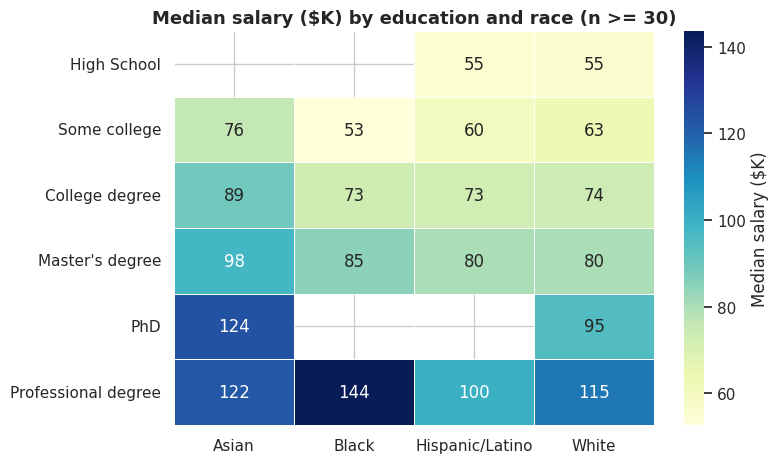

In [30]:
rows = []
for k in ["White", "Asian", "Black", "Hispanic/Latino"]:
    sub = analysis[analysis["Race: " + k] & (analysis["Education"] != "Not stated")]
    g = sub.groupby("Education")["Salary"].agg(["count", "median"])
    for e in edu_order[:-1]:
        rows.append({"Race": k, "Education": e, "median": g["median"].get(e, np.nan) if g["count"].get(e, 0) >= 30 else np.nan})
hm = pd.DataFrame(rows).pivot(index="Education", columns="Race", values="median").reindex(edu_order[:-1])
plt.figure(figsize=(8, 4.8))
sns.heatmap(hm / 1000, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5, cbar_kws={"label": "Median salary ($K)"})
plt.title("Median salary ($K) by education and race (n >= 30)"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.show()

**Education: higher education goes with higher pay, with one big jump at the top.**
- Median salary rises at each level: **High School $55K → Some college $63K → College degree $75K → Master's $80K → PhD $97K → Professional degree $120K** (MD, JD and similar).
- A professional degree pays about **2.2 times** the High School median. A Master's adds only about **$5,000 (7%)** over a College degree.

**Race: differences are modest, apart from one group.**
- **Asian** respondents have the highest median at **$92,000** (n = 1,505), about 20% above White respondents ($77,000). Black ($78,000), Native American ($77,000) and Hispanic/Latino ($75,000) respondents are within about $3,000 of the White median.
- The heatmap shows the **Asian premium holds within each education level** (for example $89K vs $74K at college level and $97.5K vs $80K at Master's level), so education alone does not explain it. At the same education level, the other groups sit close to the White median, and Black respondents with a Master's degree are higher ($85K vs $80K).
- **Caution:** race groups overlap, because people could choose more than one, and some groups are small (Middle Eastern/North African n = 153, Native American n = 125).

### Question 6. Is there a "sweet spot" between total experience and years in the current field?
**Derived feature:** `Experience Gap` = overall experience − field experience, using range midpoints. A gap of 0 means the person has spent their whole career in their current field. A large gap means they spent many years elsewhere before moving into it.

In [31]:
analysis["Experience Gap"] = analysis["Overall Years"] - analysis["Field Years"]
print("Rows where field experience is larger than overall experience (impossible, excluded):", (analysis["Experience Gap"] < 0).sum())
q6 = analysis[analysis["Experience Gap"] >= 0].copy()
q6["Gap Group"] = pd.cut(q6["Experience Gap"], bins=[-0.1, 0.1, 5.5, 10.1, 100],
                         labels=["No gap\n(0 yrs)", "Small gap\n(up to ~5 yrs)", "Medium gap\n(6-10 yrs)", "Large gap\n(11+ yrs)"])
gap_stats = q6.groupby("Gap Group", observed=True)["Salary"].agg(Respondents="count", Median="median", Mean="mean")
print(gap_stats.round(0))
print("\nSpearman correlation with salary:")
for col in ["Overall Years", "Field Years", "Experience Gap"]:
    print(f"  {col:<16}{q6[[col, 'Salary']].corr(method='spearman').iloc[0, 1]:+.2f}")

Rows where field experience is larger than overall experience (impossible, excluded): 213
                           Respondents   Median     Mean
Gap Group                                               
No gap\n(0 yrs)                  12657  84000.0  97536.0
Small gap\n(up to ~5 yrs)         3468  67000.0  76005.0
Medium gap\n(6-10 yrs)            5281  80000.0  91473.0
Large gap\n(11+ yrs)              1733  66000.0  78288.0

Spearman correlation with salary:
  Overall Years   +0.24
  Field Years     +0.34
  Experience Gap  -0.10


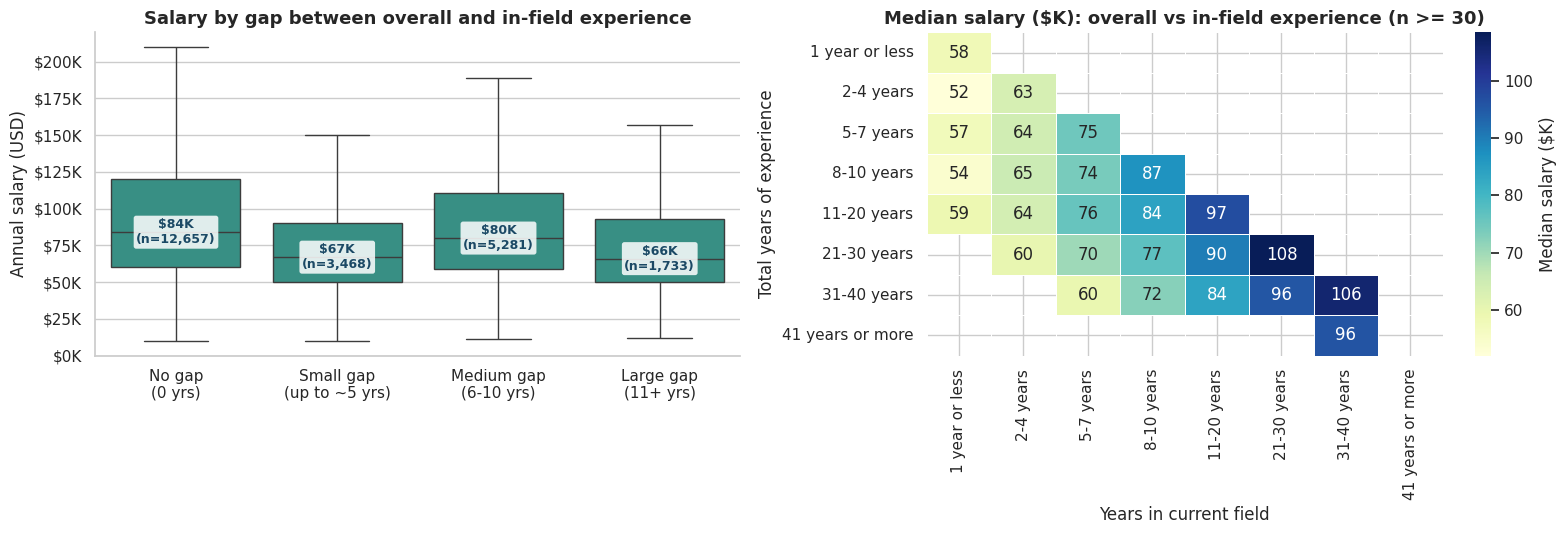

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=q6, x="Gap Group", y="Salary", color=TEAL, showfliers=False, ax=axes[0])
for i, (g, row) in enumerate(gap_stats.iterrows()):
    axes[0].text(i, row["Median"], f"${row['Median']/1000:,.0f}K\n(n={int(row['Respondents']):,})", ha="center", va="center", fontsize=9, color=NAVY, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.85))
axes[0].yaxis.set_major_formatter(money); axes[0].set_xlabel(""); axes[0].set_ylabel("Annual salary (USD)")
axes[0].set_title("Salary by gap between overall and in-field experience")

cell = q6.groupby(["Overall Experience", "Field Experience"], observed=True)["Salary"].agg(["count", "median"])
cell = cell[cell["count"] >= 30]["median"].unstack("Field Experience").reindex(index=exp_order, columns=exp_order)
sns.heatmap(cell / 1000, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5, cbar_kws={"label": "Median salary ($K)"}, ax=axes[1])
axes[1].set_title("Median salary ($K): overall vs in-field experience (n >= 30)")
axes[1].set_xlabel("Years in current field"); axes[1].set_ylabel("Total years of experience")
plt.tight_layout(); plt.show()

FINDINGS

Yes: staying in one field pays best. People whose whole career is in their current field have the highest median salary, 84,000 USD. With a small gap it is 67,000 USD, and with a large gap (11+ years elsewhere) it is 66,000 USD.
Years in your field count more than total years of work. The link to salary is +0.34 for years in the field, against +0.24 for total experience.
Same total experience, more years in the field means higher pay. For people with 11–20 years in total, the median rises from 59,000 USD to 97,000 USD.
Same years in the field, more total experience means lower pay. For people with 8–10 years in their field, the median falls from 87,000 USD to 72,000 USD.

## 5. Summary of insights

| # | Question | Answer in plain business language |
|---|---|---|
| 1 | Which industry pays the most? | **Computing or Tech**, with a median of $120,000, about 50% above the overall median. Law is next at $95,000. |
| 2 | How does salary grow with experience? | It rises about 60% from 1 year to 21–30 years ($57K to $91K), mostly in the first 20 years, then **flattens at about $90K**. |
| 3 | Same role, different locations? | Location changes pay a lot, and the best state depends on the role. For software engineers, **New York ($160K) pays about 42% more than Texas ($113K)**. |
| 4 | Gender and experience? | Women's median is **25% lower** than men's overall. The gap starts at 7% and **grows to about 33%** by 21–30 years of experience. |
| 5 | Race and education? | **Higher education goes with higher pay**, especially professional degrees ($120K). **Asian respondents earn about 20% more** at the median, and that holds within education levels. Other race groups are close together. |
| 6 | Experience "sweet spot"? | Careers spent **entirely in one field** earn the most ($84K median). Years spent in other fields add little pay value. |

**What this means**
- A person's pay is shaped most by **industry, years in the current field, education level and location**. Gender and race show gaps in this sample that deserve a closer look, but this analysis does not explain them.
- For someone planning a career, the data points to staying in a field long enough to build depth, and to professional or advanced degrees where they lead to specialised roles. It also points to Tech and Law as the highest-paying industries.
- The results describe **this survey's USD respondents**, a self-selected sample, and should be read as patterns, not guarantees.

## 6. Limitations
- **Self-reported, self-selected data.** The survey was shared through a blog, so respondents skew young, female, white and in office-based jobs. The results describe this sample and not all workers.
- **USD respondents only.** Results for other currencies are not covered.
- **Association, not cause.** Pay differences by gender, race or location are patterns in the data. This analysis does not show why they occur.
- **Experience is in ranges.** I used range midpoints, so the Experience Gap is approximate.
- **Base salary only.** Bonuses and other compensation were not included because many respondents left them blank.